In [7]:
import sys
!{sys.executable} -m pip install scikit-learn matplotlib

In [9]:
import pandas as pd
import re
import sklearn
from matplotlib import pyplot as plt
import random
from sklearn.metrics import classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

##### Chargement des données du corpus reddit

In [17]:
df_data=pd.read_excel("df_reddit_news.xlsx")

In [19]:
print(f'Taille du corpus avant suppression des doublons: {len(df_data)}')

Taille du corpus avant suppression des doublons: 5251


In [23]:
print(f'Taille du corpus après suppression des doublons: {len(df_data)}')

Taille du corpus après suppression des doublons: 5251


In [25]:
neg=df_data[df_data["annotation"]==0]
print(f"Nombre d'instances négatives: {len(neg)}")

Nombre d'instances négatives: 2947


In [27]:
pos=df_data[df_data["annotation"]==1]
print(f"Nombre d'instances positives: {len(pos)}")

Nombre d'instances positives: 2304


In [29]:
print(len(neg)+len(pos))

5251


In [31]:
df_data.value_counts(subset="annotation")

annotation
0    2947
1    2304
Name: count, dtype: int64

### Prétraitement des données

In [33]:
# fonctions pour nettoyage des données
def rep_urls(text):
    text = re.sub(r'https?://\S+|www\.\S+', 'URL', text)
    return text

In [35]:
def rep_gif(text):
    text=re.sub(r'!gif\b.*', 'GIF_TOKEN', text)
    return text

In [37]:
import re

def clean_text(text):
    if not isinstance(text, str):
        return text

    # Newlines and tabs
    text = text.replace("\n", " ")
    text = text.replace("\t", " ")

    # Non-breaking spaces
    text = text.replace("\xa0", " ")

    # Optional: remove other escaped hex artifacts that appear literally
    text = re.sub(r"\\x[a-fA-F0-9]{2}", " ", text)

    # Collapse multiple spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

##### Nettoyage du corpus reddit

In [39]:
df_data["clean_text"] = df_data["text"].apply(clean_text)
df_data["clean_text"]=df_data["clean_text"].apply(rep_urls)
df_data["clean_text"]=df_data["clean_text"].apply(rep_gif)

In [43]:
print(df_data["clean_text"][0])

Les français aiment-ils tellement se plaindre qu'ils ne résolvent pas volontairement certains problèmes ?|>certains francais se plaignent de pas réussir à épargner, Mais c'est vrai, il suffit de rien dépenser pendant un mois, pour avoir un salaire d'avance et ne plus avoir des fins de mois difficile /s


##### Diviser les données en données de test et de dev

In [45]:
df_data = df_data.sample(frac=1, random_state=1).reset_index(drop=True)

In [47]:
from sklearn.model_selection import train_test_split

train_df,temp_df=train_test_split(
    df_data,
    test_size=0.2,
    random_state=42,
    stratify=df_data["annotation"])

dev_df,test_df=train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["annotation"])

In [49]:
vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(train_df["text"])
X_dev   = vectorizer.transform(dev_df["text"])
X_test  = vectorizer.transform(test_df["text"])

In [51]:
y_train=train_df["annotation"]
y_dev=dev_df["annotation"]
y_test=test_df["annotation"]

In [53]:
clf=LinearSVC(random_state=42)

In [55]:
clf.fit(X_train,y_train)

LinearSVC(random_state=42)

In [57]:
dev_pred=clf.predict(X_dev)

In [61]:
print("Classification report pour les données de développement")
print("---------------------------------------------------------------")
print(classification_report(y_dev,dev_pred, target_names=["non sarcastic","sarcastic"]))

Classification report pour les données de développement
---------------------------------------------------------------
               precision    recall  f1-score   support

non sarcastic       0.82      0.88      0.85       295
    sarcastic       0.84      0.75      0.79       230

     accuracy                           0.83       525
    macro avg       0.83      0.82      0.82       525
 weighted avg       0.83      0.83      0.83       525



In [63]:
test_pred=clf.predict(X_test)

In [65]:
print("Classification report pour les données de test")
print("---------------------------------------------------------------")
print(classification_report(y_test,test_pred, target_names=["non sarcastic","sarcastic"]))

Classification report pour les données de test
---------------------------------------------------------------
               precision    recall  f1-score   support

non sarcastic       0.81      0.92      0.86       295
    sarcastic       0.87      0.72      0.79       231

     accuracy                           0.83       526
    macro avg       0.84      0.82      0.82       526
 weighted avg       0.84      0.83      0.83       526



In [67]:
!pip freeze > requirements.txt

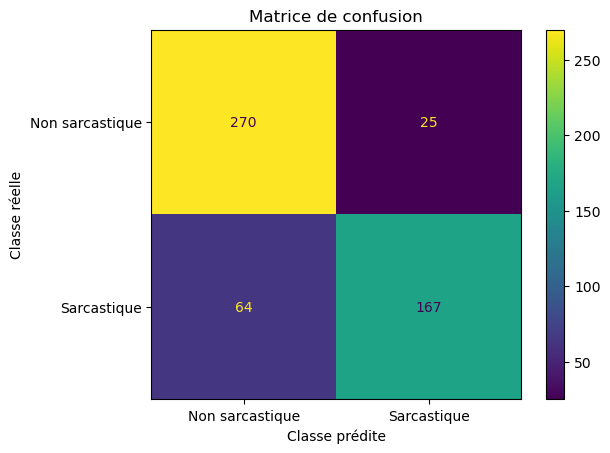

In [69]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcul de la matrice de confusion
cm = confusion_matrix(y_test, test_pred)

# Affichage
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non sarcastique", "Sarcastique"]
)

disp.plot(values_format="d")

plt.title("Matrice de confusion")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.show()